# Multicolinealidad en la ecuación de salarios de Mincer
## Proyecto de Fundamentos de Econometría — todos los temas del segundo parcial con datos reales

**Pregunta central:** ¿cuánto aumenta el salario un año más de educación, y qué pasa con nuestras
estimaciones cuando los regresores (educación, experiencia, edad, habilidad, entorno familiar) están muy
correlacionados entre sí?

El cuaderno recorre, en el orden de las notas del curso, **todos** los temas: regresión lineal simple,
4.1–4.9 (supuestos, parámetros, pruebas t y F, dummies, R², precios hedónicos, modelos no anidados,
regresión cuantílica, aplicaciones financieras), multicolinealidad (correlaciones, VIF, tolerancia,
autovalores, número de condición), MANOVA, y 5.1–5.13 (residuos, heteroscedasticidad, Breusch–Pagan,
autocorrelación, Durbin–Watson, Breusch–Godfrey, HAC, modelos dinámicos, rezagos y Jarque–Bera).

**Datos reales**

| Base | Fuente | Uso |
|---|---|---|
| `wage2` | Wooldridge (NLS, EE. UU., 1980), 935 hombres | Base principal: Mincer y multicolinealidad |
| `hprice1` | Wooldridge, 88 casas en Boston | 4.6 Precios hedónicos |
| `px.data.stocks()` | Plotly, precios semanales 2018–2019 | 4.9 Aplicaciones financieras, autocorrelación |
| `macrodata` | statsmodels, EE. UU. trimestral 1959–2009 | 5.7–5.12 Autocorrelación, dinámica y rezagos |

Convención (notas, p. 3): SSR = suma de cuadrados **residual**, SSE = **explicada**, SST = total.

In [1]:
# En Google Colab hay que instalar el paquete de datos de Wooldridge (las demás librerías ya vienen):
%pip install -q wooldridge


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python3.13 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import wooldridge
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from statsmodels.multivariate.manova import MANOVA
from statsmodels.regression.quantile_regression import QuantReg
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import acorr_breusch_godfrey, het_breuschpagan, het_white, linear_reset
from statsmodels.stats.outliers_influence import OLSInfluence, variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.4f}".format)

# Paleta y estilo del cuaderno de regresión simple del curso
TINTA, AZUL, NARANJA, VERDE, GRIS, FONDO = "#1d2433", "#2f6f9f", "#d1603d", "#4c8b5b", "#9aa3b2", "#fbfaf8"
mpl.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": TINTA, "axes.linewidth": 0.9, "axes.labelcolor": TINTA,
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlepad": 12,
    "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": TINTA, "ytick.color": TINTA, "text.color": TINTA,
    "font.family": "DejaVu Sans", "figure.dpi": 110, "savefig.dpi": 200,
    "grid.color": "#dfe3e8", "axes.grid": True, "axes.axisbelow": True, "legend.frameon": False,
})

try:
    FIG = Path(__file__).resolve().parent.parent / "figuras"
except NameError:  # dentro de Jupyter / Colab
    FIG = Path("figuras")
FIG.mkdir(exist_ok=True)
R = {}  # aquí se guardan todos los números que usan el reporte, la presentación y el Beamer


def guardar(nombre):
    plt.tight_layout()
    plt.savefig(FIG / f"{nombre}.png")
    plt.show()
    plt.close("all")


def vif_tabla(X):
    """VIF y tolerancia con constante en las regresiones auxiliares (notas 3, código 4)."""
    Xc = sm.add_constant(X)
    v = [variance_inflation_factor(Xc.values, j + 1) for j in range(X.shape[1])]
    out = pd.DataFrame({"VIF": v, "Tolerancia": 1 / np.array(v)}, index=X.columns)
    return out.sort_values("VIF", ascending=False)


def fmt_p(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"

## 0. Datos y lenguaje mínimo

Variable dependiente $Y$: `lwage` (log del salario mensual). Regresores $X_j$: educación, experiencia,
antigüedad, edad, IQ, KWW (conocimiento del mundo laboral), escolaridad de los padres y dummies.
Se eliminan las observaciones con escolaridad de los padres faltante.

In [3]:
w2 = wooldridge.data("wage2")
cols = ["wage", "lwage", "educ", "exper", "tenure", "age", "IQ", "KWW", "meduc", "feduc",
        "sibs", "brthord", "married", "black", "south", "urban", "hours"]
df = w2[cols].dropna(subset=["meduc", "feduc"]).reset_index(drop=True)
df["exper_c"] = df.exper - df.exper.mean()
df["peduc"] = (df.meduc + df.feduc) / 2
df["pexper"] = df.age - df.educ - 6
n = len(df)
R["n"] = n
print(f"n = {n} (de {len(w2)} originales)")
print(df.head())
desc = df[["wage", "lwage", "educ", "exper", "tenure", "age", "IQ", "KWW", "meduc", "feduc"]].describe().T
R["descriptivos"] = desc[["mean", "std", "min", "max"]].round(2).to_dict("index")
desc

n = 722 (de 935 originales)
   wage  lwage  educ  exper  tenure  age   IQ  KWW   meduc   feduc  sibs  \
0   769 6.6451    12     11       2   31   93   35  8.0000  8.0000     1   
1   808 6.6946    18     11      16   37  119   41 14.0000 14.0000     1   
2   825 6.7154    14     11       9   33  108   46 14.0000 14.0000     1   
3   650 6.4770    12     13       7   32   96   32 12.0000 12.0000     4   
4   562 6.3315    11     14       5   34   74   27  6.0000 11.0000    10   

   brthord  married  black  south  urban  hours  exper_c   peduc  pexper  
0   2.0000        1      0      0      1     40  -0.3338  8.0000      13  
1      NaN        1      0      0      1     50  -0.3338 14.0000      13  
2   2.0000        1      0      0      1     40  -0.3338 14.0000      13  
3   3.0000        1      0      0      1     40   1.6662 12.0000      14  
4   6.0000        1      0      0      1     40   2.6662  8.5000      17  


,count,mean,std,min,25%,50%,75%,max
wage,722.0000,977.0983,408.0922,115.0000,684.0000,923.0000,1200.0000,3078.0000
lwage,722.0000,6.7999,0.4194,4.7449,6.5280,6.8276,7.0901,8.0320
educ,722.0000,13.6634,2.2368,9.0000,12.0000,13.0000,16.0000,18.0000
exper,722.0000,11.3338,4.2493,1.0000,8.0000,11.0000,15.0000,22.0000
tenure,722.0000,7.1898,5.0249,0.0000,3.0000,7.0000,11.0000,22.0000
age,722.0000,32.9003,3.0883,28.0000,30.0000,32.0000,36.0000,38.0000
IQ,722.0000,102.1177,14.7718,54.0000,93.0000,103.0000,112.0000,145.0000
KWW,722.0000,35.8753,7.6790,12.0000,31.0000,37.0000,41.0000,56.0000
meduc,722.0000,10.8061,2.8286,0.0000,9.0000,12.0000,12.0000,18.0000
feduc,722.0000,10.2548,3.3058,0.0000,8.0000,10.5000,12.0000,18.0000


| Objeto | En este proyecto |
|---|---|
| $Y_i$ | `lwage` del trabajador $i$ |
| $\beta_j$ | efecto parcial poblacional (desconocido) |
| $\hat\beta_j$ | estimación MCO con la muestra de 722 trabajadores |
| $\varepsilon_i$ vs $\hat\varepsilon_i$ | error no observado vs residuo calculado |
| $se(\hat\beta_j)$ | precisión del estimador (¡no la dispersión del salario!) |

## 1. Regresión lineal simple: $\ln(w_i)=\beta_0+\beta_1\,educ_i+u_i$

Mismas fórmulas del cuaderno de regresión simple: $\hat\beta_1=S_{xy}/S_{xx}$, $\hat\beta_0=\bar y-\hat\beta_1\bar x$,
$R^2=\hat\rho_{xy}^2$, y las ecuaciones normales $\sum\hat u_i=0$, $\sum x_i\hat u_i=0$.

In [4]:
def mco(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    xb, yb = x.mean(), y.mean()
    dx, dy = x - xb, y - yb
    Sxx, Syy, Sxy = dx @ dx, dy @ dy, dx @ dy
    b1 = Sxy / Sxx
    b0 = yb - b1 * xb
    yhat = b0 + b1 * x
    u = y - yhat
    SSR = u @ u
    SSE = Syy - SSR
    return dict(x=x, y=y, n=x.size, xb=xb, yb=yb, Sxx=Sxx, Syy=Syy, Sxy=Sxy, b0=b0, b1=b1,
                yhat=yhat, u=u, SST=Syy, SSE=SSE, SSR=SSR, R2=SSE / Syy, rho=Sxy / np.sqrt(Sxx * Syy))


rs = mco(df.educ, df.lwage)
sig2 = rs["SSR"] / (rs["n"] - 2)
se_b1 = np.sqrt(sig2 / rs["Sxx"])
se_b0 = np.sqrt(sig2 * (1 / rs["n"] + rs["xb"] ** 2 / rs["Sxx"]))
t_b1 = rs["b1"] / se_b1
tcrit = stats.t.ppf(0.975, rs["n"] - 2)
F_s = (rs["SSE"] / 1) / (rs["SSR"] / (rs["n"] - 2))
print(f"x̄ = {rs['xb']:.4f}  ȳ = {rs['yb']:.4f}   Sxx = {rs['Sxx']:.3f}  Sxy = {rs['Sxy']:.3f}  Syy = {rs['Syy']:.3f}")
print(f"β̂1 = Sxy/Sxx = {rs['b1']:.5f}   β̂0 = {rs['b0']:.5f}")
print(f"SST = {rs['SST']:.3f} = SSE {rs['SSE']:.3f} + SSR {rs['SSR']:.3f}   R² = {rs['R2']:.4f} = ρ̂² = {rs['rho']**2:.4f}")
print(f"Σû = {rs['u'].sum():.1e}   Σx·û = {rs['x'] @ rs['u']:.1e}   Σŷ·û = {rs['yhat'] @ rs['u']:.1e}")
print(f"se(β̂1) = {se_b1:.5f}   t = {t_b1:.3f}   t_crit(0.025,{rs['n']-2}) = {tcrit:.3f}")
print(f"IC95% β1 = [{rs['b1']-tcrit*se_b1:.4f}, {rs['b1']+tcrit*se_b1:.4f}]   F = {F_s:.3f} = t² = {t_b1**2:.3f}")
m_s = smf.ols("lwage ~ educ", df).fit()
print("\nComprobación con statsmodels:\n", m_s.summary().tables[1])
print(anova_lm(m_s))
R["simple"] = dict(xb=rs["xb"], yb=rs["yb"], Sxx=rs["Sxx"], Sxy=rs["Sxy"], Syy=rs["Syy"], b0=rs["b0"], b1=rs["b1"],
                   SSE=rs["SSE"], SSR=rs["SSR"], R2=rs["R2"], rho=rs["rho"], se_b1=se_b1, se_b0=se_b0, t=t_b1,
                   tcrit=tcrit, ic=[rs["b1"] - tcrit * se_b1, rs["b1"] + tcrit * se_b1], F=F_s,
                   p=2 * stats.t.sf(abs(t_b1), rs["n"] - 2), efecto_exacto=100 * (np.exp(rs["b1"]) - 1))

x̄ = 13.6634  ȳ = 6.7999   Sxx = 3607.215  Sxy = 211.414  Syy = 126.812
β̂1 = Sxy/Sxx = 0.05861   β̂0 = 5.99913
SST = 126.812 = SSE 12.391 + SSR 114.421   R² = 0.0977 = ρ̂² = 0.0977
Σû = -6.0e-14   Σx·û = -1.1e-12   Σŷ·û = -4.8e-13
se(β̂1) = 0.00664   t = 8.830   t_crit(0.025,720) = 1.963
IC95% β1 = [0.0456, 0.0716]   F = 77.969 = t² = 77.969

Comprobación con statsmodels:
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      5.9991      0.092     65.282      0.000       5.819       6.180
educ           0.0586      0.007      8.830      0.000       0.046       0.072
               df   sum_sq  mean_sq       F  PR(>F)
educ       1.0000  12.3907  12.3907 77.9692  0.0000
Residual 720.0000 114.4212   0.1589     NaN     NaN


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


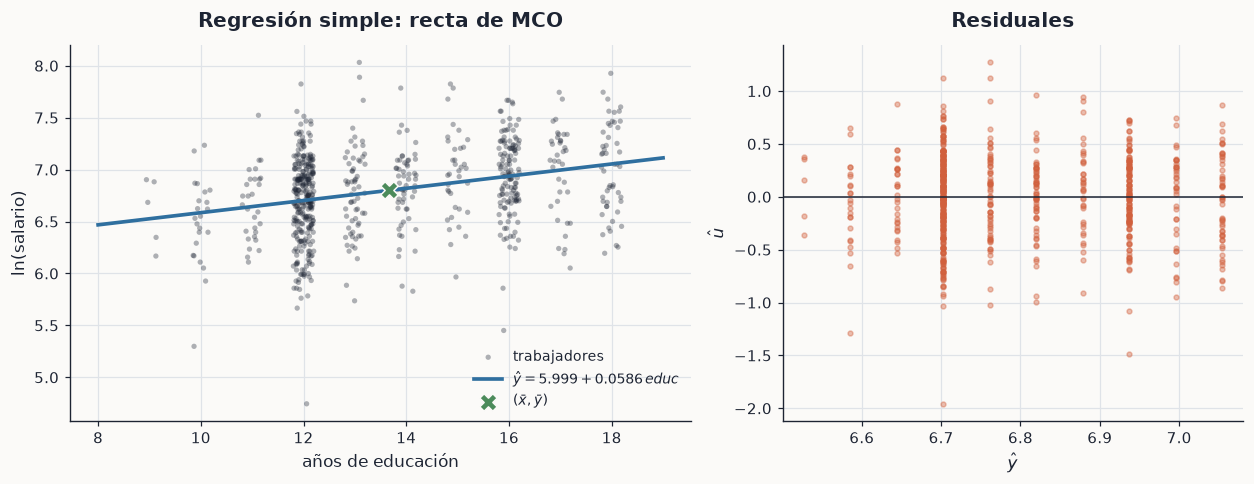

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.5), gridspec_kw={"width_ratios": [1.35, 1]})
jit = np.random.default_rng(1).uniform(-0.2, 0.2, n)
a1.scatter(df.educ + jit, df.lwage, s=12, color=TINTA, alpha=0.35, ec="none", label="trabajadores")
gx = np.linspace(8, 19, 50)
a1.plot(gx, rs["b0"] + rs["b1"] * gx, color=AZUL, lw=2.4,
        label=f"$\\hat y = {rs['b0']:.3f} + {rs['b1']:.4f}\\,educ$")
a1.scatter([rs["xb"]], [rs["yb"]], s=130, marker="X", color=VERDE, zorder=4, ec=FONDO, label=r"$(\bar x,\bar y)$")
a1.set(xlabel="años de educación", ylabel="ln(salario)", title="Regresión simple: recta de MCO")
a1.legend(loc="lower right", fontsize=9)
a2.scatter(rs["yhat"], rs["u"], s=10, color=NARANJA, alpha=0.4)
a2.axhline(0, color=TINTA, lw=1)
a2.set(xlabel=r"$\hat y$", ylabel=r"$\hat u$", title="Residuales")
guardar("simple_recta")

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


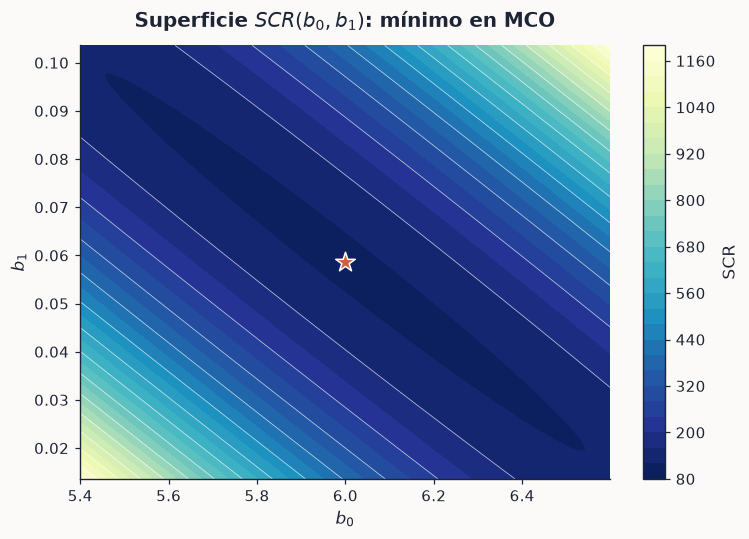

corr(β̂0, β̂1) = -0.9869


In [6]:
# Superficie SCR(b0, b1): el mínimo es el punto de MCO
b0g = np.linspace(rs["b0"] - 0.6, rs["b0"] + 0.6, 150)
b1g = np.linspace(rs["b1"] - 0.045, rs["b1"] + 0.045, 150)
B0, B1 = np.meshgrid(b0g, b1g)
x_, y_ = rs["x"], rs["y"]
SCR = (np.sum(y_ ** 2) - 2 * B0 * y_.sum() - 2 * B1 * (x_ @ y_) + n * B0 ** 2
       + 2 * B0 * B1 * x_.sum() + B1 ** 2 * (x_ @ x_))
fig, ax = plt.subplots(figsize=(7, 5))
cf = ax.contourf(B0, B1, SCR, levels=28, cmap="YlGnBu_r")
ax.contour(B0, B1, SCR, levels=14, colors="white", linewidths=0.5, alpha=0.7)
ax.scatter([rs["b0"]], [rs["b1"]], s=180, marker="*", color=NARANJA, ec="white", zorder=5)
ax.set(xlabel="$b_0$", ylabel="$b_1$", title="Superficie $SCR(b_0,b_1)$: mínimo en MCO")
ax.grid(False)
fig.colorbar(cf, ax=ax, label="SCR")
guardar("simple_scr")
# Nota: la elipse es muy alargada porque b0 y b1 están muy correlacionados (x̄ = 13.5 lejos de 0):
# es una "multicolinealidad" entre la constante y educ. Centrar x la vuelve circular.
R["simple"]["corr_b0_b1"] = float(m_s.cov_params().iloc[0, 1] / (m_s.bse.iloc[0] * m_s.bse.iloc[1]))
print("corr(β̂0, β̂1) =", round(R["simple"]["corr_b0_b1"], 4))

In [7]:
# Sensibilidad a observaciones influyentes (en vez de inventar un atípico, usamos la distancia de Cook real)
cook = OLSInfluence(m_s).cooks_distance[0]
top = np.argsort(cook)[::-1][:10]
m_sin = smf.ols("lwage ~ educ", df.drop(index=top)).fit()
print(f"10 observaciones más influyentes (Cook) → β̂1: {m_s.params['educ']:.5f} → {m_sin.params['educ']:.5f}")
R["simple"]["b1_sin_influyentes"] = m_sin.params["educ"]
R["simple"]["cook_max"] = float(cook.max())

# Reescalamiento: x' = 12·educ (meses), y' = wage/1000 (miles de USD) en el modelo nivel-nivel
r_niv = mco(df.educ, df.wage)
r_esc = mco(12 * df.educ, df.wage / 1000)
print(f"nivel-nivel β̂1 = {r_niv['b1']:.4f}  →  reescalado β̂1' = {r_esc['b1']:.7f} = (c/b)β̂1 = {r_niv['b1']/1000/12:.7f}")
print(f"R² original = {r_niv['R2']:.6f}  R² reescalado = {r_esc['R2']:.6f}  (invariante)")
R["simple"]["nivel_b1"] = r_niv["b1"]
R["simple"]["nivel_b0"] = r_niv["b0"]
R["simple"]["nivel_R2"] = r_niv["R2"]

# Regresión sobre una dummy = diferencia de medias
r_d = mco(df.urban, df.lwage)
g0, g1 = df.lwage[df.urban == 0].mean(), df.lwage[df.urban == 1].mean()
print(f"lwage ~ urban: β̂0 = {r_d['b0']:.5f} = ȳ_rural {g0:.5f};  β̂1 = {r_d['b1']:.5f} = ȳ_urb − ȳ_rural = {g1-g0:.5f}")
R["simple"]["dummy"] = dict(b0=r_d["b0"], b1=r_d["b1"], y0=g0, y1=g1)

10 observaciones más influyentes (Cook) → β̂1: 0.05861 → 0.06012
nivel-nivel β̂1 = 58.5939  →  reescalado β̂1' = 0.0048828 = (c/b)β̂1 = 0.0048828
R² original = 0.103140  R² reescalado = 0.103140  (invariante)
lwage ~ urban: β̂0 = 6.65211 = ȳ_rural 6.65211;  β̂1 = 0.20484 = ȳ_urb − ȳ_rural = 0.20484


MCO: media 0.0586 var 4.40e-05 | alternativo: media 0.0585 var 8.73e-05


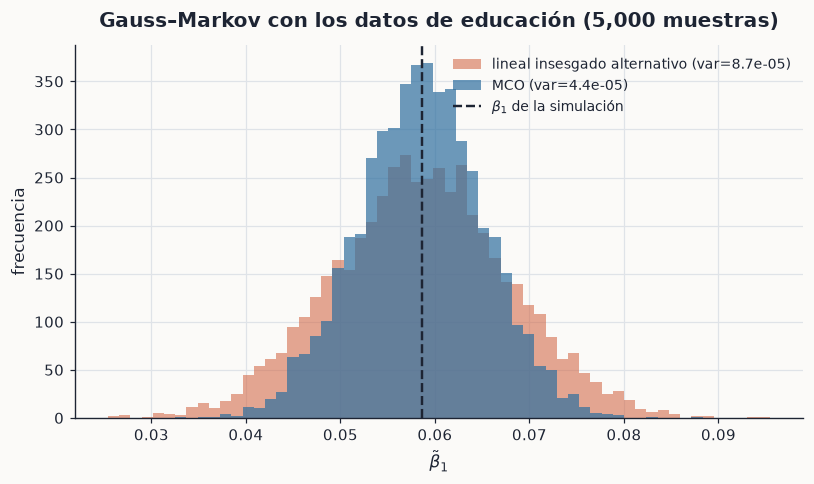

In [8]:
# Gauss–Markov con los x reales (educ fija) y parámetros iguales a los estimados
xg = df.educ.values.astype(float)
dxg = xg - xg.mean()
Sxxg = dxg @ dxg
c_mco = dxg / Sxxg
rng = np.random.default_rng(2026)
d = rng.normal(size=n)
d -= d.mean()
d -= (d @ dxg) / Sxxg * dxg  # Σd = 0 y Σd·x = 0 → el competidor sigue siendo insesgado
d = d / np.sqrt(d @ d) * np.sqrt(1 / Sxxg)
c_alt = c_mco + d
Ysim = rs["b0"] + rs["b1"] * xg + rng.normal(0, np.sqrt(sig2), size=(5000, n))
b_mco, b_alt = Ysim @ c_mco, Ysim @ c_alt
print(f"MCO: media {b_mco.mean():.4f} var {b_mco.var():.2e} | alternativo: media {b_alt.mean():.4f} var {b_alt.var():.2e}")
R["gauss_markov"] = dict(var_mco=b_mco.var(), var_alt=b_alt.var(), media_mco=b_mco.mean(), media_alt=b_alt.mean())
fig, ax = plt.subplots(figsize=(7.5, 4.5))
bins = np.linspace(min(b_mco.min(), b_alt.min()), max(b_mco.max(), b_alt.max()), 60)
ax.hist(b_alt, bins=bins, color=NARANJA, alpha=0.55, label=f"lineal insesgado alternativo (var={b_alt.var():.1e})")
ax.hist(b_mco, bins=bins, color=AZUL, alpha=0.7, label=f"MCO (var={b_mco.var():.1e})")
ax.axvline(rs["b1"], color=TINTA, ls="--", lw=1.6, label=r"$\beta_1$ de la simulación")
ax.set(xlabel=r"$\tilde\beta_1$", ylabel="frecuencia", title="Gauss–Markov con los datos de educación (5,000 muestras)")
ax.legend(fontsize=9)
guardar("gauss_markov")

## 2. (4.1) Supuestos del modelo de regresión lineal múltiple

Modelo de trabajo (Mincer ampliado):
$$\ln w_i=\beta_0+\beta_1 educ_i+\beta_2 exper_i+\beta_3 exper_i^2+\beta_4 tenure_i+\dots+\varepsilon_i$$

| Supuesto | ¿Se cumple aquí? | Evidencia en este cuaderno |
|---|---|---|
| Linealidad en parámetros | Sí: $exper^2$ y logs son transformaciones de $X$ | RESET (sección 5) |
| Muestra aleatoria | Corte transversal de la NLS | — |
| **No colinealidad perfecta** | Falla si se incluye $pexper=age-educ-6$ | rango de $X$ (sección 9) |
| Media condicional cero | Dudoso sin habilidad: educación capta habilidad | caída de $\hat\beta_{educ}$ al agregar IQ |
| Homoscedasticidad | Breusch–Pagan la rechaza al 5% | sección 12 |
| No autocorrelación | Irrelevante en corte transversal aleatorio | sección 13 |
| Normalidad | Rechazada (JB), pero $n=722$ es grande | sección 16 |

## 3. (4.2) Parámetros: estimación e interpretación ceteris paribus

In [9]:
f_base = "lwage ~ educ + exper + I(exper**2)"
f_full = ("lwage ~ educ + exper + I(exper**2) + tenure + age + IQ + KWW + meduc + feduc"
          " + married + black + south + urban")
f_red = "lwage ~ educ + exper_c + I(exper_c**2) + tenure + IQ + peduc + married + black + south + urban"
m_base = smf.ols(f_base, df).fit()
m_full = smf.ols(f_full, df).fit()
m_red = smf.ols(f_red, df).fit()
coefs = pd.DataFrame({"coef": m_full.params, "ee": m_full.bse, "t": m_full.tvalues, "p": m_full.pvalues,
                      "IC inf": m_full.conf_int()[0], "IC sup": m_full.conf_int()[1]})
print(coefs)
R["full"] = dict(params=m_full.params.to_dict(), bse=m_full.bse.to_dict(), t=m_full.tvalues.to_dict(),
                 p=m_full.pvalues.to_dict(), R2=m_full.rsquared, R2a=m_full.rsquared_adj, F=m_full.fvalue,
                 Fp=m_full.f_pvalue, k=int(m_full.df_model), df_resid=int(m_full.df_resid),
                 SSR=m_full.ssr, SSE=m_full.ess, aic=m_full.aic, bic=m_full.bic)
R["base"] = dict(params=m_base.params.to_dict(), bse=m_base.bse.to_dict(), t=m_base.tvalues.to_dict(),
                 R2=m_base.rsquared, R2a=m_base.rsquared_adj, aic=m_base.aic, bic=m_base.bic)

                 coef     ee       t      p  IC inf  IC sup
Intercept      4.9167 0.2289 21.4845 0.0000  4.4674  5.3661
educ           0.0408 0.0089  4.5867 0.0000  0.0234  0.0583
exper          0.0159 0.0146  1.0909 0.2757 -0.0127  0.0446
I(exper ** 2) -0.0001 0.0007 -0.2238 0.8230 -0.0014  0.0012
tenure         0.0079 0.0029  2.7130 0.0068  0.0022  0.0135
age            0.0066 0.0063  1.0533 0.2925 -0.0057  0.0190
IQ             0.0037 0.0012  3.0377 0.0025  0.0013  0.0060
KWW            0.0029 0.0023  1.2315 0.2185 -0.0017  0.0074
meduc          0.0076 0.0060  1.2567 0.2093 -0.0043  0.0194
feduc          0.0058 0.0053  1.0920 0.2752 -0.0046  0.0163
married        0.1949 0.0436  4.4728 0.0000  0.1093  0.2804
black         -0.0773 0.0523 -1.4784 0.1397 -0.1800  0.0254
south         -0.0679 0.0303 -2.2407 0.0254 -0.1273 -0.0084
urban          0.1796 0.0310  5.7894 0.0000  0.1187  0.2404


In [10]:
# Las cuatro formas funcionales con educación
formas = {"Nivel–nivel": "wage ~ educ", "Log–nivel": "lwage ~ educ",
          "Nivel–log": "wage ~ np.log(educ)", "Log–log": "lwage ~ np.log(educ)"}
ff = []
for nom, f in formas.items():
    m = smf.ols(f, df).fit()
    b = m.params.iloc[1]
    lect = {"Nivel–nivel": f"+1 año → +{b:.1f} USD/mes",
            "Log–nivel": f"+1 año → +{100*b:.1f}% (exacto {100*(np.exp(b)-1):.1f}%)",
            "Nivel–log": f"+1% educ → +{b/100:.2f} USD/mes",
            "Log–log": f"elasticidad: +1% educ → +{b:.2f}%"}[nom]
    ff.append({"forma": nom, "modelo": f, "beta": b, "R2": m.rsquared, "lectura": lect})
formas_df = pd.DataFrame(ff)
R["formas"] = ff
formas_df

,forma,modelo,beta,R2,lectura
0,Nivel–nivel,wage ~ educ,58.5939,0.1031,+1 año → +58.6 USD/mes
1,Log–nivel,lwage ~ educ,0.0586,0.0977,+1 año → +5.9% (exacto 6.0%)
2,Nivel–log,wage ~ np.log(educ),816.2814,0.1035,+1% educ → +8.16 USD/mes
3,Log–log,lwage ~ np.log(educ),0.8206,0.0990,elasticidad: +1% educ → +0.82%


## 4. (4.3) Prueba F: significancia conjunta y restricciones

$$F=\frac{(SSR_R-SSR_{NR})/q}{SSR_{NR}/(n-k-1)}\overset{H_0}{\sim}F_{q,\,n-k-1}$$

In [11]:
# ANOVA y F global del modelo completo
k = int(m_full.df_model)
dfr = int(m_full.df_resid)
MSR, MSE = m_full.ess / k, m_full.ssr / dfr
print(f"SST = {m_full.centered_tss:.3f} = SSE {m_full.ess:.3f} + SSR {m_full.ssr:.3f}")
print(f"MSR = {MSR:.4f}  MSE = {MSE:.4f}  F = {MSR/MSE:.3f}  F_crit(0.05;{k},{dfr}) = {stats.f.ppf(.95,k,dfr):.3f}  p = {m_full.f_pvalue:.2e}")
R["anova"] = dict(SST=m_full.centered_tss, SSE=m_full.ess, SSR=m_full.ssr, MSR=MSR, MSE=MSE, F=MSR / MSE,
                  k=k, dfr=dfr, Fcrit=stats.f.ppf(.95, k, dfr), p=m_full.f_pvalue)


def prueba_F(no_restr, restr, q, nombre):
    F = ((restr.ssr - no_restr.ssr) / q) / (no_restr.ssr / no_restr.df_resid)
    gl2 = int(no_restr.df_resid)
    out = dict(H0=nombre, q=q, gl2=gl2, SSR_R=restr.ssr, SSR_NR=no_restr.ssr, F=F,
               Fcrit=stats.f.ppf(0.95, q, gl2), p=stats.f.sf(F, q, gl2))
    out["decision"] = "Rechaza H0" if out["p"] < 0.05 else "No rechaza H0"
    return out


pruebas = []
# (a) bloque de habilidad y entorno familiar
m_sin_hab = smf.ols("lwage ~ educ + exper + I(exper**2) + tenure + age + married + black + south + urban", df).fit()
pruebas.append(prueba_F(m_full, m_sin_hab, 4, "β_IQ = β_KWW = β_meduc = β_feduc = 0"))
# (b) ciclo de vida: exper, exper², age (el síntoma de multicolinealidad)
m_sin_cv = smf.ols("lwage ~ educ + tenure + IQ + KWW + meduc + feduc + married + black + south + urban", df).fit()
pruebas.append(prueba_F(m_full, m_sin_cv, 3, "β_exper = β_exper² = β_age = 0"))
# (c) región: south y urban
m_sin_reg = smf.ols(f_full.replace(" + south + urban", ""), df).fit()
pruebas.append(prueba_F(m_full, m_sin_reg, 2, "β_south = β_urban = 0"))
# (d) una sola restricción → F = t²
m_sin_age = smf.ols(f_full.replace(" + age", ""), df).fit()
pf = prueba_F(m_full, m_sin_age, 1, "β_age = 0")
pf["t2"] = m_full.tvalues["age"] ** 2
pruebas.append(pf)
# (e) restricción lineal no nula: β_meduc = β_feduc (q = 1) → sustituir por meduc + feduc
m_igual = smf.ols(f_full.replace("meduc + feduc", "I(meduc + feduc)"), df).fit()
pe = prueba_F(m_full, m_igual, 1, "β_meduc = β_feduc")
pruebas.append(pe)
pruebas_df = pd.DataFrame(pruebas)
print(m_full.f_test("meduc = feduc"))  # comprobación
R["pruebas_F"] = pruebas
pruebas_df[["H0", "q", "gl2", "SSR_R", "SSR_NR", "F", "Fcrit", "p", "decision"]]

SST = 126.812 = SSE 33.510 + SSR 93.302
MSR = 2.5777  MSE = 0.1318  F = 19.560  F_crit(0.05;13,708) = 1.734  p = 1.76e-39
<F test: F=0.03235039454857545, p=0.8573122519020195, df_denom=708, df_num=1>


,H0,q,gl2,SSR_R,SSR_NR,F,Fcrit,p,decision
0,β_IQ = β_KWW = β_meduc = β_feduc = 0,4,708,96.1571,93.3020,5.4163,2.3845,0.0003,Rechaza H0
1,β_exper = β_exper² = β_age = 0,3,708,95.4665,93.3020,5.4747,2.6175,0.0010,Rechaza H0
2,β_south = β_urban = 0,2,708,98.9111,93.3020,21.2816,3.0084,0.0000,Rechaza H0
3,β_age = 0,1,708,93.4483,93.3020,1.1095,3.8546,0.2925,No rechaza H0
4,β_meduc = β_feduc,1,708,93.3063,93.3020,0.0324,3.8546,0.8573,No rechaza H0


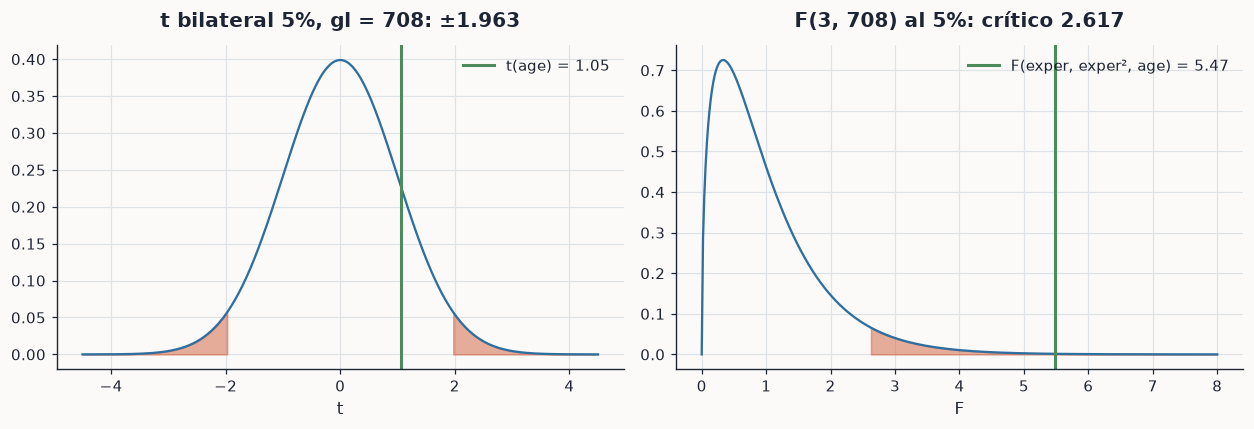

In [12]:
# Regiones de rechazo t y F (cómo se ve la prueba antes de calcularla)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4))
xx = np.linspace(-4.5, 4.5, 400)
tc = stats.t.ppf(0.975, dfr)
a1.plot(xx, stats.t.pdf(xx, dfr), color=AZUL)
for lado in (xx < -tc, xx > tc):
    a1.fill_between(xx[lado], stats.t.pdf(xx[lado], dfr), color=NARANJA, alpha=0.5)
ta = m_full.tvalues["age"]
a1.axvline(ta, color=VERDE, lw=2, label=f"t(age) = {ta:.2f}")
a1.set(title=f"t bilateral 5%, gl = {dfr}: ±{tc:.3f}", xlabel="t")
a1.legend()
fx = np.linspace(0, 8, 400)
Fobs = pruebas[1]["F"]
fcrit = stats.f.ppf(0.95, 3, dfr)
a2.plot(fx, stats.f.pdf(fx, 3, dfr), color=AZUL)
a2.fill_between(fx[fx > fcrit], stats.f.pdf(fx[fx > fcrit], 3, dfr), color=NARANJA, alpha=0.5)
a2.axvline(Fobs, color=VERDE, lw=2, label=f"F(exper, exper², age) = {Fobs:.2f}")
a2.set(title=f"F(3, {dfr}) al 5%: crítico {fcrit:.3f}", xlabel="F")
a2.legend()
guardar("regiones_rechazo")

**Lectura:** `age` no es significativa sola (t pequeño), pero exper, exper² y age **juntas** sí lo son.
Es exactamente la "Lección del ejercicio 1" de la guía de pruebas t y F: cuando las regresoras están muy
correlacionadas, los datos no pueden separar sus efectos individuales aunque el bloque sí explique.

## 5. (4.4) Variables cualitativas: dummies e interacciones

In [13]:
m_int = smf.ols("lwage ~ educ + exper + tenure + IQ + married + black + south + urban + educ:black", df).fit()
print(m_int.summary().tables[1])
b = m_int.params
R["dummies"] = dict(
    married=b["married"], black=b["black"], south=b["south"], urban=b["urban"],
    educ=b["educ"], educ_black=b["educ:black"], p_int=m_int.pvalues["educ:black"],
    pend_black=b["educ"] + b["educ:black"],
    married_exacto=100 * (np.exp(b["married"]) - 1), urban_exacto=100 * (np.exp(b["urban"]) - 1),
    dif_black_12=b["black"] + 12 * b["educ:black"])
print(f"Pendiente educ: base (no negros) = {b['educ']:.4f};  negros = β_educ + γ = {b['educ']+b['educ:black']:.4f}")
print(f"Diferencia negros − base con 12 años de educación = δ + 12γ = {R['dummies']['dif_black_12']:.4f}")

# Trampa de las dummies: urban + rural + constante → colinealidad perfecta
df["rural"] = 1 - df.urban
Xt = sm.add_constant(df[["educ", "urban", "rural"]])
R["trampa_rango"] = [int(np.linalg.matrix_rank(Xt.values)), Xt.shape[1]]
print("Rango con urban + rural + constante:", R["trampa_rango"])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      5.1108      0.144     35.594      0.000       4.829       5.393
educ           0.0541      0.008      6.788      0.000       0.038       0.070
exper          0.0158      0.004      4.189      0.000       0.008       0.023
tenure         0.0085      0.003      2.977      0.003       0.003       0.014
IQ             0.0042      0.001      3.649      0.000       0.002       0.006
married        0.1984      0.044      4.559      0.000       0.113       0.284
black          0.2048      0.331      0.618      0.537      -0.446       0.855
south         -0.0737      0.030     -2.448      0.015      -0.133      -0.015
urban          0.1893      0.031      6.147      0.000       0.129       0.250
educ:black    -0.0246      0.026     -0.954      0.340      -0.075       0.026
Pendiente educ: base (no negros) = 0.0541;  negros =

Categorías base: `married=0` (no casado), `black=0`, `south=0` (fuera del sur), `urban=0` (rural).
Con interacción, el coeficiente de `black` por sí solo sólo es la diferencia cuando educ = 0; hay que
sumar coeficientes para obtener la pendiente o la diferencia en un nivel razonable de educación.

## 6. (4.5) $R^2$ y $R^2$ ajustada

In [14]:
r2rows = []
for nom, f in [("Completo", f_full), ("+ sibs", f_full + " + sibs"), ("+ sibs + brthord", f_full + " + sibs + brthord"),
               ("+ hours", f_full + " + hours")]:
    m = smf.ols(f, df.dropna(subset=["brthord"])).fit()
    r2rows.append({"modelo": nom, "k": int(m.df_model), "R2": m.rsquared, "R2_aj": m.rsquared_adj})
r2_df = pd.DataFrame(r2rows)
R["r2"] = r2rows
r2_df

,modelo,k,R2,R2_aj
0,Completo,13,0.2778,0.2633
1,+ sibs,14,0.2780,0.2624
2,+ sibs + brthord,15,0.2802,0.2635
3,+ hours,14,0.2897,0.2743


Agregar regresoras **nunca** baja $R^2$, pero $\bar R^2$ puede bajar si la variable no reduce lo
suficiente la SSR. Ninguno de los dos prueba causalidad.

## 7. (4.6) Precios hedónicos — base `hprice1` (88 casas)
$\ln P_i=\beta_0+\beta_1\ln(lotsize_i)+\beta_2\ln(sqrft_i)+\beta_3\,bdrms_i+\beta_4\,colonial_i+u_i$

In [15]:
hp = wooldridge.data("hprice1")
m_h = smf.ols("lprice ~ llotsize + lsqrft + bdrms + colonial", hp).fit()
print(m_h.summary().tables[1])
vif_h = vif_tabla(hp[["llotsize", "lsqrft", "bdrms", "colonial"]])
m_h2 = smf.ols("lprice ~ llotsize + lsqrft + bdrms + colonial + lassess", hp).fit()
vif_h2 = vif_tabla(hp[["llotsize", "lsqrft", "bdrms", "colonial", "lassess"]])
print(vif_h, "\n", vif_h2)
R["hedonico"] = dict(params=m_h.params.to_dict(), p=m_h.pvalues.to_dict(), R2=m_h.rsquared,
                     bdrms_exacto=100 * (np.exp(m_h.params["bdrms"]) - 1),
                     vif=vif_h.VIF.to_dict(), vif_assess=vif_h2.VIF.to_dict(),
                     se_lsqrft=m_h.bse["lsqrft"], se_lsqrft_assess=m_h2.bse["lsqrft"],
                     corr_sqrft_bdrms=hp[["lsqrft", "bdrms"]].corr().iloc[0, 1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.3496      0.651     -2.073      0.041      -2.644      -0.055
llotsize       0.1678      0.038      4.395      0.000       0.092       0.244
lsqrft         0.7072      0.093      7.620      0.000       0.523       0.892
bdrms          0.0268      0.029      0.934      0.353      -0.030       0.084
colonial       0.0538      0.045      1.202      0.233      -0.035       0.143
            VIF  Tolerancia
bdrms    1.4990      0.6671
lsqrft   1.4791      0.6761
llotsize 1.1074      0.9030
colonial 1.1068      0.9035 
             VIF  Tolerancia
lassess  6.2551      0.1599
lsqrft   5.1048      0.1959
llotsize 1.7455      0.5729
bdrms    1.4991      0.6671
colonial 1.1083      0.9023


**Lectura:** el coeficiente de `lsqrft` es una elasticidad (precio implícito de la superficie). Al
agregar el avalúo (`lassess`), que se construye a partir de los mismos atributos, el VIF de `lsqrft` sube de
≈1.5 a ≈5.1 y su error estándar aumenta ≈49%: otro ejemplo real de multicolinealidad. `bdrms` no es
significativo condicional en la superficie: más recámaras en la misma superficie no agregan valor.

## 8. (4.7) Modelos no anidados
Modelo A (habilidad: IQ, KWW) vs. Modelo B (entorno familiar: meduc, feduc). Ninguno es restricción del otro,
así que la F clásica no aplica: usamos AIC/BIC y la prueba J de Davidson–MacKinnon.

In [16]:
comunes = "lwage ~ educ + exper + I(exper**2) + tenure + married + black + south + urban"
mA = smf.ols(comunes + " + IQ + KWW", df).fit()
mB = smf.ols(comunes + " + meduc + feduc", df).fit()
dJ = df.assign(yhatA=mA.fittedvalues, yhatB=mB.fittedvalues)
jA = smf.ols(comunes + " + IQ + KWW + yhatB", dJ).fit()  # ¿B aporta algo a A?
jB = smf.ols(comunes + " + meduc + feduc + yhatA", dJ).fit()  # ¿A aporta algo a B?
R["no_anidados"] = dict(aicA=mA.aic, bicA=mA.bic, aicB=mB.aic, bicB=mB.bic,
                        R2aA=mA.rsquared_adj, R2aB=mB.rsquared_adj,
                        tJ_A=jA.tvalues["yhatB"], pJ_A=jA.pvalues["yhatB"],
                        tJ_B=jB.tvalues["yhatA"], pJ_B=jB.pvalues["yhatA"])
pd.DataFrame(R["no_anidados"], index=["valor"]).T

,valor
aicA,599.6814
bicA,650.0836
aicB,609.0573
bicB,659.4595
R2aA,0.2476
R2aB,0.2378
tJ_A,2.2086
pJ_A,0.0275
tJ_B,3.7717
pJ_B,0.0002


**Lectura:** AIC, BIC y $\bar R^2$ prefieren A (habilidad). Pero la prueba J rechaza en **ambas** direcciones
($\hat y_B$ aporta a A y $\hat y_A$ aporta a B): ninguno de los dos modelos abarca al otro, lo que justifica un
modelo que combine ambos bloques… y que precisamente por eso tiene multicolinealidad.

## 9. (4.8) Regresión cuantílica: ¿el retorno a la educación es igual en toda la distribución?

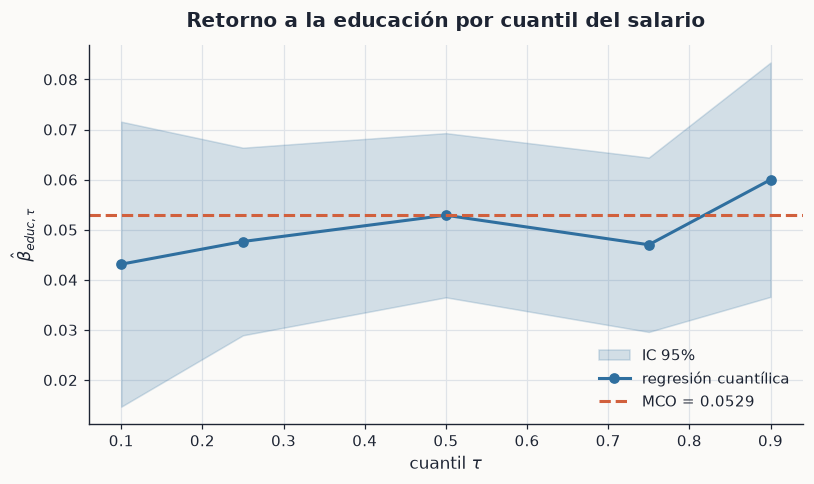

,tau,beta_educ,ee,inf,sup
0,0.1000,0.0431,0.0145,0.0147,0.0716
1,0.2500,0.0476,0.0095,0.0289,0.0664
2,0.5000,0.0529,0.0083,0.0365,0.0693
3,0.7500,0.0470,0.0089,0.0296,0.0644
4,0.9000,0.0600,0.0119,0.0366,0.0834


In [17]:
f_q = "lwage ~ educ + exper + tenure + IQ + married + black + south + urban"
qs = [0.10, 0.25, 0.50, 0.75, 0.90]
qrows = []
for q in qs:
    mq = smf.quantreg(f_q, df).fit(q=q)
    ci = mq.conf_int().loc["educ"]
    qrows.append({"tau": q, "beta_educ": mq.params["educ"], "ee": mq.bse["educ"], "inf": ci[0], "sup": ci[1]})
q_df = pd.DataFrame(qrows)
b_ols_q = smf.ols(f_q, df).fit().params["educ"]
R["cuantil"] = dict(tabla=qrows, ols=b_ols_q)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.fill_between(q_df.tau, q_df.inf, q_df.sup, color=AZUL, alpha=0.2, label="IC 95%")
ax.plot(q_df.tau, q_df.beta_educ, "o-", color=AZUL, lw=2, label="regresión cuantílica")
ax.axhline(b_ols_q, color=NARANJA, ls="--", lw=2, label=f"MCO = {b_ols_q:.4f}")
ax.set(xlabel=r"cuantil $\tau$", ylabel=r"$\hat\beta_{educ,\tau}$", title="Retorno a la educación por cuantil del salario")
ax.legend()
guardar("cuantilica")
q_df

**Lectura:** el retorno va de ≈4.3% (τ = 0.10) a ≈6.0% (τ = 0.90), pero los intervalos se traslapan: la
heterogeneidad es moderada y la pendiente media de MCO resume razonablemente bien la relación.

## 10. (4.9) Aplicaciones financieras — acciones tecnológicas (rendimientos log semanales, 2018–2019)

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0022      0.003      0.770      0.443      -0.003       0.008
MKT_EW         0.7831      0.092      8.485      0.000       0.600       0.966
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0012      0.003      0.387      0.699      -0.005       0.008
MSFT           0.5593      0.191      2.926      0.004       0.180       0.939
AMZN           0.1119      0.119      0.941      0.349      -0.124       0.348
GOOG           0.0947      0.138      0.684      0.495      -0.180       0.369
        VIF  Tolerancia
MSFT 2.6974      0.3707
GOOG 2.1447      0.4663
AMZN 2.1106      0.4738


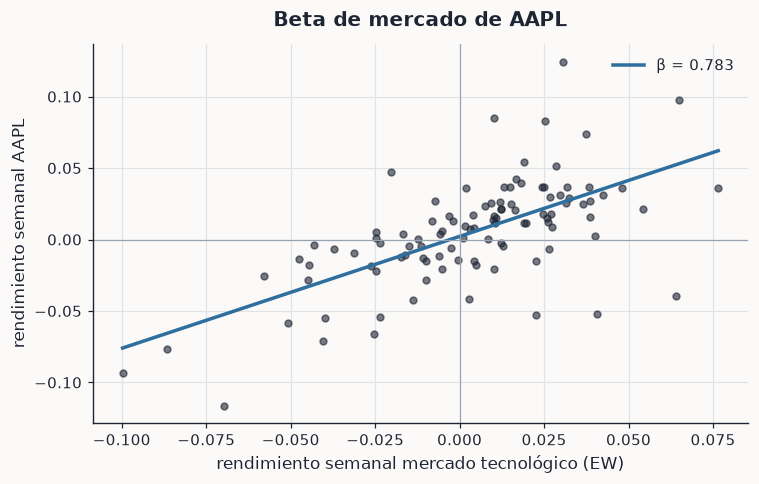

In [18]:
stk = px.data.stocks()
ret = np.log(stk[["GOOG", "AAPL", "AMZN", "FB", "NFLX", "MSFT"]]).diff()
ret["MKT_EW"] = ret.mean(axis=1)
ret["date"] = pd.to_datetime(stk["date"])
ret = ret.dropna().reset_index(drop=True)
m_capm = smf.ols("AAPL ~ MKT_EW", ret).fit()
m_fac = smf.ols("AAPL ~ MSFT + AMZN + GOOG", ret).fit()
vif_s = vif_tabla(ret[["MSFT", "AMZN", "GOOG"]])
bp_c = het_breuschpagan(m_capm.resid, m_capm.model.exog)
bg_c = acorr_breusch_godfrey(m_capm, nlags=4)
jb_c = jarque_bera(m_capm.resid)
R["finanzas"] = dict(
    n=int(m_capm.nobs), beta=m_capm.params["MKT_EW"], se_beta=m_capm.bse["MKT_EW"], alpha=m_capm.params["Intercept"],
    p_alpha=m_capm.pvalues["Intercept"], ic_beta=m_capm.conf_int().loc["MKT_EW"].tolist(), R2_capm=m_capm.rsquared,
    fac_params=m_fac.params.to_dict(), fac_p=m_fac.pvalues.to_dict(), fac_R2=m_fac.rsquared, fac_F=m_fac.fvalue,
    fac_Fp=m_fac.f_pvalue, vif=vif_s.VIF.to_dict(), corr=ret[["MSFT", "AMZN", "GOOG"]].corr().round(3).values.tolist(),
    bp_p=bp_c[1], bg_LM=bg_c[0], bg_p=bg_c[1], dw=durbin_watson(m_capm.resid), jb=jb_c[0], jb_p=jb_c[1])
print(m_capm.summary().tables[1], "\n", m_fac.summary().tables[1])
print(vif_s)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(ret.MKT_EW, ret.AAPL, s=20, color=TINTA, alpha=0.6)
gx = np.linspace(ret.MKT_EW.min(), ret.MKT_EW.max(), 50)
ax.plot(gx, m_capm.params.iloc[0] + m_capm.params.iloc[1] * gx, color=AZUL, lw=2.3,
        label=f"β = {m_capm.params.iloc[1]:.3f}")
ax.axhline(0, color=GRIS, lw=0.8)
ax.axvline(0, color=GRIS, lw=0.8)
ax.set(xlabel="rendimiento semanal mercado tecnológico (EW)", ylabel="rendimiento semanal AAPL",
       title="Beta de mercado de AAPL")
ax.legend()
guardar("capm")

En el modelo de AAPL sobre MSFT, AMZN y GOOG, las tres acciones se mueven juntas: la F global es alta pero
sólo MSFT es significativa individualmente. De nuevo: significancia conjunta ≠ significancia individual.

## 11. Multicolinealidad: diagnóstico completo (el corazón del proyecto)
### 11.1 Multicolinealidad perfecta: experiencia potencial

In [19]:
Xp = sm.add_constant(df[["educ", "age", "pexper"]])
R["perfecta"] = dict(rango=int(np.linalg.matrix_rank(Xp.values)), cols=Xp.shape[1],
                     cond=float(np.linalg.cond(Xp.T @ Xp)), eig_min=float(np.linalg.eigvalsh(Xp.T @ Xp).min()))
print(R["perfecta"])

{'rango': 3, 'cols': 4, 'cond': 9.620117341596814e+16, 'eig_min': -2.5152800048119105e-12}


### 11.2 Matriz de correlaciones

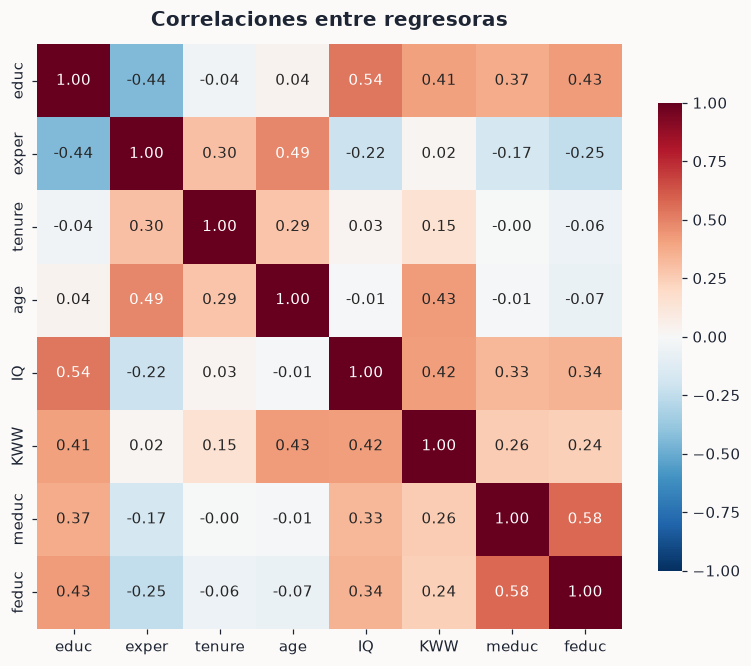

In [20]:
Xv = ["educ", "exper", "tenure", "age", "IQ", "KWW", "meduc", "feduc"]
corr = df[Xv].corr()
R["corr"] = corr.round(2).values.tolist()
R["corr_vars"] = Xv
plt.figure(figsize=(7.2, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .8})
plt.title("Correlaciones entre regresoras")
guardar("correlaciones")

### 11.3 VIF, tolerancia y regresiones auxiliares (regla de Klein)

In [21]:
Xfull = pd.DataFrame(m_full.model.exog, columns=m_full.model.exog_names).drop(columns="Intercept")
Xfull.columns = [c.replace("I(exper ** 2)", "exper²") for c in Xfull.columns]
vif_full = vif_tabla(Xfull)
vif_full["R2_aux"] = 1 - 1 / vif_full.VIF
vif_full["Klein (R2_aux > R2)"] = vif_full.R2_aux > m_full.rsquared
R["vif_full"] = vif_full.drop(columns="Klein (R2_aux > R2)").to_dict("index")
R["corr_exper_exper2"] = np.corrcoef(df.exper, df.exper ** 2)[0, 1]
R["corr_experc"] = np.corrcoef(df.exper_c, df.exper_c ** 2)[0, 1]
vif_full

,VIF,Tolerancia,R2_aux,Klein (R2_aux > R2)
exper²,24.0103,0.0416,0.9584,True
exper,21.0784,0.0474,0.9526,True
educ,2.1710,0.4606,0.5394,True
age,2.0689,0.4834,0.5166,True
KWW,1.7390,0.5750,0.4250,True
IQ,1.7328,0.5771,0.4229,True
feduc,1.6948,0.5900,0.4100,True
meduc,1.5849,0.6309,0.3691,True
black,1.2276,0.8146,0.1854,False
tenure,1.1588,0.8630,0.1370,False


### 11.4 Autovalores, índices de condición y número de condición (regresoras estandarizadas)

In [22]:
Z = StandardScaler().fit_transform(Xfull)
eig = np.linalg.eigvalsh(np.corrcoef(Z, rowvar=False))[::-1]
ic = np.sqrt(eig.max() / eig)
R["autovalores"] = eig.tolist()
R["indices_condicion"] = ic.tolist()
R["num_cond_estandarizado"] = float(np.linalg.cond(Z))
Xn = m_full.model.exog / np.linalg.norm(m_full.model.exog, axis=0)
R["num_cond_bkw"] = float(np.linalg.cond(Xn))  # Belsley–Kuh–Welsch (columnas normalizadas, con constante)
print(pd.DataFrame({"autovalor": eig, "índice de condición": ic}).round(4))
print(f"Número de condición (Z estandarizada) = {R['num_cond_estandarizado']:.2f};  BKW con constante = {R['num_cond_bkw']:.1f}")

    autovalor  índice de condición
0      3.2731               1.0000
1      2.4228               1.1623
2      1.1479               1.6886
3      1.0816               1.7396
4      0.9298               1.8762
5      0.9136               1.8927
6      0.8061               2.0150
7      0.7086               2.1492
8      0.5780               2.3798
9      0.4290               2.7621
10     0.3975               2.8696
11     0.2894               3.3632
12     0.0226              12.0400
Número de condición (Z estandarizada) = 12.04;  BKW con constante = 77.3


### 11.5 Prueba de Farrar–Glauber
$\chi^2=-[n-1-(2k+5)/6]\ln|R|\sim\chi^2_{k(k-1)/2}$

In [23]:
kk = Xfull.shape[1]
detR = np.linalg.det(np.corrcoef(Xfull.values, rowvar=False))
fg = -(n - 1 - (2 * kk + 5) / 6) * np.log(detR)
glfg = kk * (kk - 1) / 2
R["farrar"] = dict(detR=detR, chi2=fg, gl=glfg, crit=stats.chi2.ppf(.95, glfg), p=stats.chi2.sf(fg, glfg))
R["farrar"]

{'detR': np.float64(0.0030767296067255975),
 'chi2': np.float64(4140.299871134814),
 'gl': 78.0,
 'crit': np.float64(99.61692732428385),
 'p': np.float64(0.0)}

### 11.6 Síntomas: errores estándar inflados y t individuales débiles

In [24]:
sint = pd.DataFrame({
    "coef base": m_base.params, "ee base": m_base.bse, "t base": m_base.tvalues,
    "coef completo": m_full.params, "ee completo": m_full.bse, "t completo": m_full.tvalues,
}).loc[["educ", "exper", "I(exper ** 2)"]]
sint

,coef base,ee base,t base,coef completo,ee completo,t completo
educ,0.0783,0.0073,10.7643,0.0408,0.0089,4.5867
exper,0.0087,0.0153,0.5693,0.0159,0.0146,1.0909
I(exper ** 2),0.0006,0.0007,0.9344,-0.0001,0.0007,-0.2238


### 11.7 Soluciones: centrar, eliminar/combinar, componentes principales y Ridge

In [25]:
f_c = f_full.replace("exper + I(exper**2)", "exper_c + I(exper_c**2)")
m_c = smf.ols(f_c, df).fit()
Z_h = StandardScaler().fit_transform(df[["IQ", "KWW", "meduc", "feduc"]])
pca = PCA().fit(Z_h)
df["cp1"] = pca.transform(Z_h)[:, 0]
m_pca = smf.ols("lwage ~ educ + exper_c + I(exper_c**2) + tenure + cp1 + married + black + south + urban", df).fit()
cols_r = ["educ", "exper", "tenure", "age", "IQ", "KWW", "meduc", "feduc", "married", "black", "south", "urban"]
Xr = df[cols_r].assign(exper2=df.exper ** 2)
sc = StandardScaler().fit(Xr)
ridge = RidgeCV(alphas=np.logspace(-3, 4, 200)).fit(sc.transform(Xr), df.lwage)
ols_std = LinearRegression().fit(sc.transform(Xr), df.lwage)


def vmax(m):
    X = pd.DataFrame(m.model.exog, columns=m.model.exog_names).drop(columns="Intercept")
    return vif_tabla(X).VIF.max()


modelos = {"Base": m_base, "Completo": m_full, "Centrado": m_c, "Reducido": m_red, "PCA": m_pca}
comp = pd.DataFrame({nm: {"beta_educ": m.params["educ"], "ee_educ": m.bse["educ"], "R2": m.rsquared,
                          "R2_aj": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic, "VIF_max": vmax(m),
                          "k": int(m.df_model)} for nm, m in modelos.items()}).T
R["comparacion"] = comp.to_dict("index")
R["pca"] = dict(var=pca.explained_variance_ratio_.tolist(), cargas=pca.components_[0].tolist())
R["ridge"] = dict(alpha=ridge.alpha_, ols=dict(zip(Xr.columns, ols_std.coef_)), ridge=dict(zip(Xr.columns, ridge.coef_)))
R["vif_centrado_max"] = vmax(m_c)
R["vif_reducido"] = vif_tabla(pd.DataFrame(m_red.model.exog, columns=m_red.model.exog_names).drop(columns="Intercept")).VIF.to_dict()
print(comp)

          beta_educ  ee_educ     R2  R2_aj      AIC      BIC  VIF_max       k
Base         0.0783   0.0073 0.1409 0.1373 691.4907 709.8188  20.3896  3.0000
Completo     0.0408   0.0089 0.2642 0.2507 599.6030 663.7514  24.0103 13.0000
Centrado     0.0408   0.0089 0.2642 0.2507 599.6030 663.7514   2.1710 13.0000
Reducido     0.0479   0.0082 0.2597 0.2492 598.0934 648.4956   1.8396 10.0000
PCA          0.0468   0.0083 0.2600 0.2507 595.7343 641.5545   1.8898  9.0000


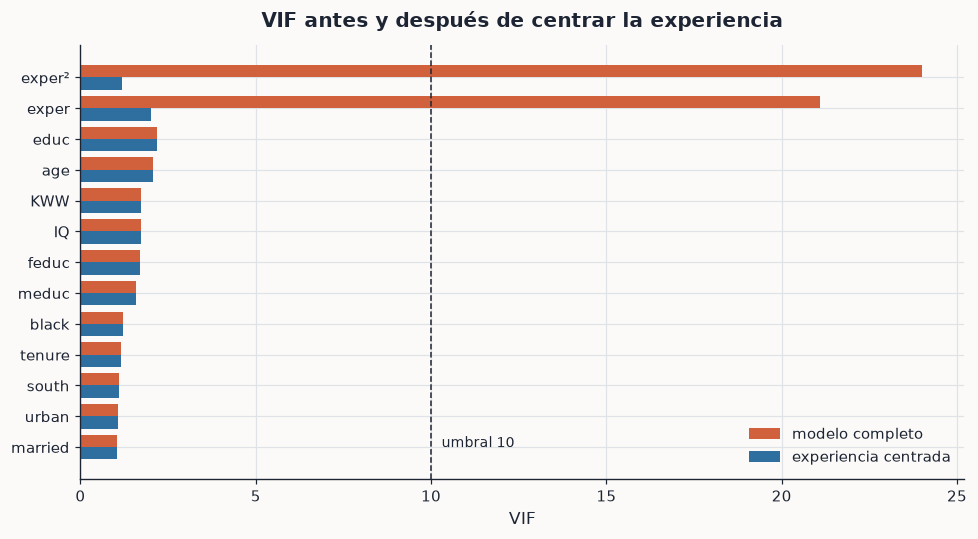

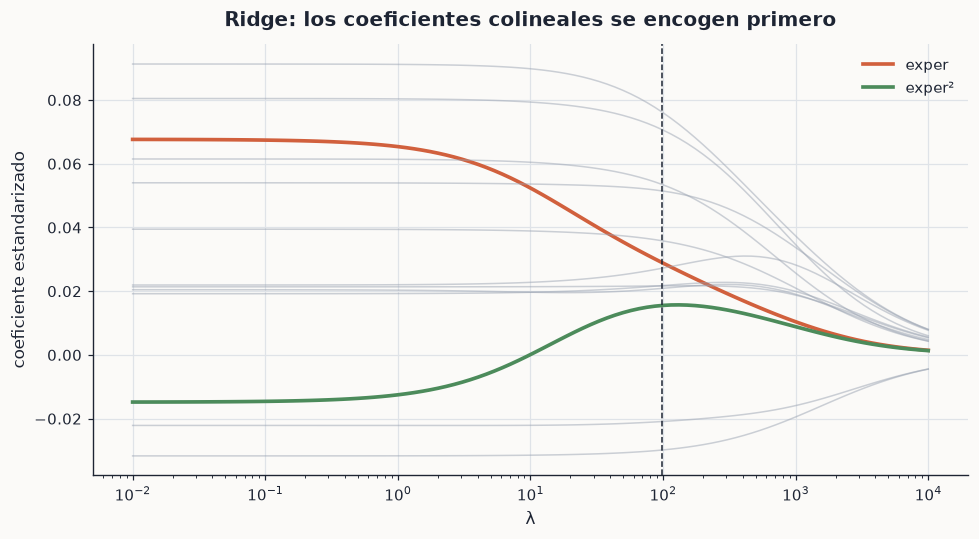

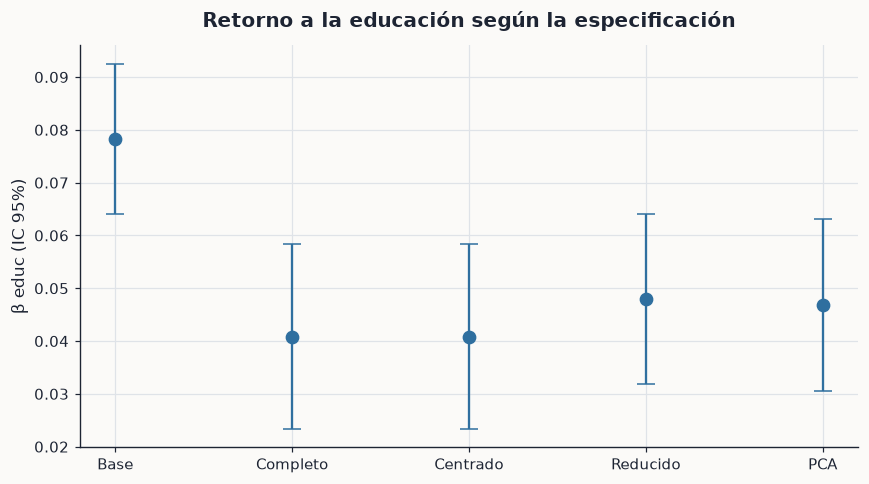

In [26]:
fig, ax = plt.subplots(figsize=(9, 5))
vc = vif_tabla(pd.DataFrame(m_c.model.exog, columns=m_c.model.exog_names).drop(columns="Intercept")).VIF
vc.index = [i.replace("I(exper_c ** 2)", "exper²").replace("exper_c", "exper") for i in vc.index]
vv = vif_full.VIF.sort_values()
y = np.arange(len(vv))
ax.barh(y + .2, vv.values, .4, color=NARANJA, label="modelo completo")
ax.barh(y - .2, vc.reindex(vv.index).values, .4, color=AZUL, label="experiencia centrada")
ax.set_yticks(y, vv.index)
ax.axvline(10, ls="--", color=TINTA, lw=1)
ax.text(10.3, 0, "umbral 10", fontsize=9)
ax.set(xlabel="VIF", title="VIF antes y después de centrar la experiencia")
ax.legend(loc="lower right")
guardar("vif")

alphas = np.logspace(-2, 4, 100)
coefs_r = np.array([Ridge(alpha=a).fit(sc.transform(Xr), df.lwage).coef_ for a in alphas])
fig, ax = plt.subplots(figsize=(9, 5))
for j, c in enumerate(Xr.columns):
    hl = c in ("exper", "exper2")
    ax.plot(alphas, coefs_r[:, j], lw=2.4 if hl else 1, alpha=1 if hl else .5,
            color=(NARANJA if c == "exper" else VERDE) if hl else GRIS, label=("exper²" if c == "exper2" else c) if hl else None)
ax.set_xscale("log")
ax.axvline(ridge.alpha_, ls="--", color=TINTA, lw=1)
ax.set(xlabel="λ", ylabel="coeficiente estandarizado", title="Ridge: los coeficientes colineales se encogen primero")
ax.legend()
guardar("ridge")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(comp.index, comp.beta_educ, yerr=1.96 * comp.ee_educ, fmt="o", color=AZUL, capsize=6, ms=8)
ax.set(ylabel="β educ (IC 95%)", title="Retorno a la educación según la especificación")
guardar("educ")

## 12. MANOVA (no es una prueba de multicolinealidad)
¿Difieren conjuntamente educación, IQ y KWW entre trabajadores del sur y del resto del país?

In [27]:
mv = MANOVA.from_formula("educ + IQ + KWW ~ C(south)", df).mv_test()
st = mv.results["C(south)"]["stat"]
R["manova"] = {k2: dict(valor=float(st.loc[k2, "Value"]), F=float(st.loc[k2, "F Value"]),
                        num=float(st.loc[k2, "Num DF"]), den=float(st.loc[k2, "Den DF"]), p=float(st.loc[k2, "Pr > F"]))
               for k2 in st.index}
print(st)

                        Value Num DF   Den DF F Value Pr > F
Wilks' lambda          0.9737      3 718.0000  6.4636 0.0003
Pillai's trace         0.0263 3.0000 718.0000  6.4636 0.0003
Hotelling-Lawley trace 0.0270      3 718.0000  6.4636 0.0003
Roy's greatest root    0.0270      3      718  6.4636 0.0003


MANOVA responde por **varias respuestas** simultáneas (aquí educ, IQ y KWW). La multicolinealidad es una
propiedad de las **columnas de X**. Son preguntas distintas.

## 13. (5.1–5.2) Distribución de los residuos y diagnóstico gráfico (modelo reducido)

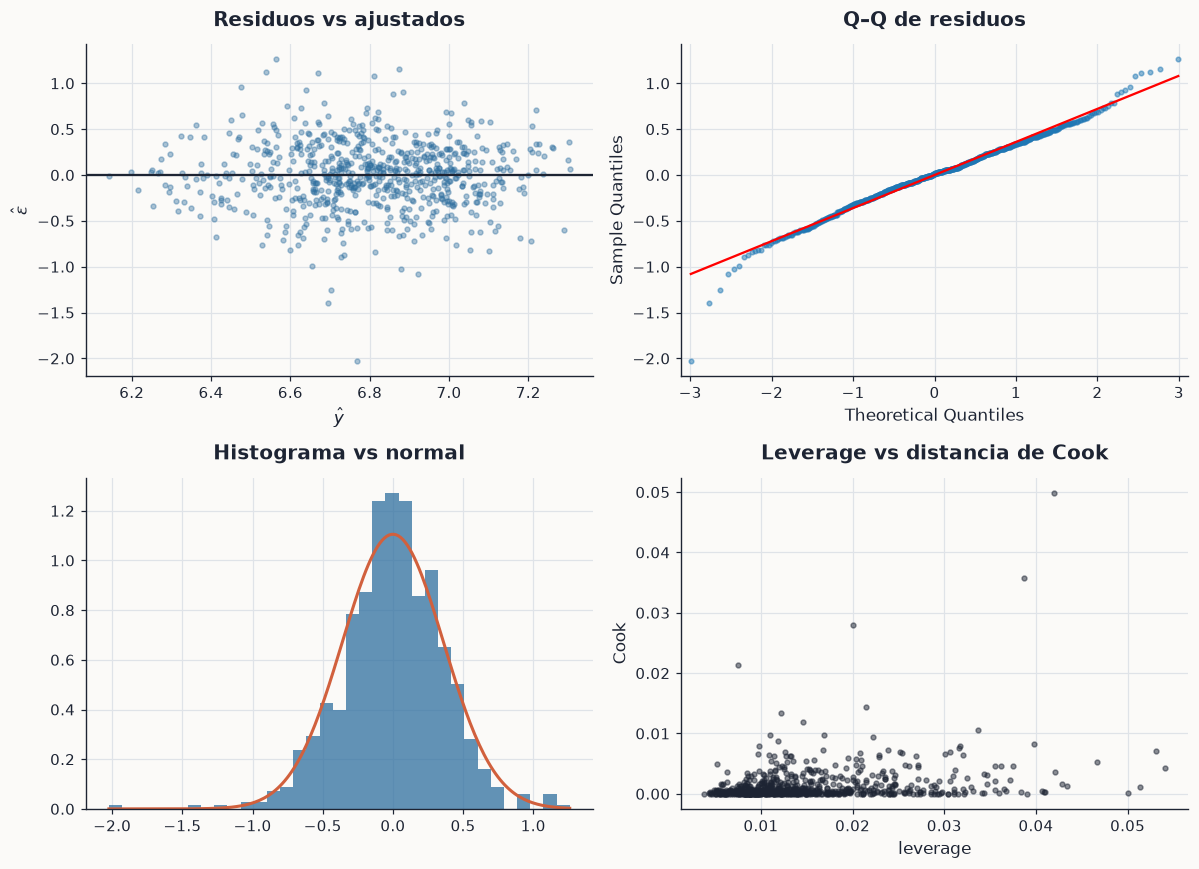

In [28]:
infl = OLSInfluence(m_red)
fig, axs = plt.subplots(2, 2, figsize=(11, 8))
axs[0, 0].scatter(m_red.fittedvalues, m_red.resid, s=10, color=AZUL, alpha=.4)
axs[0, 0].axhline(0, color=TINTA)
axs[0, 0].set(title="Residuos vs ajustados", xlabel=r"$\hat y$", ylabel=r"$\hat\varepsilon$")
sm.qqplot(m_red.resid, line="s", ax=axs[0, 1], markersize=3, alpha=.5)
axs[0, 1].set_title("Q–Q de residuos")
axs[1, 0].hist(m_red.resid, bins=35, color=AZUL, alpha=.75, density=True)
xs = np.linspace(m_red.resid.min(), m_red.resid.max(), 200)
axs[1, 0].plot(xs, stats.norm.pdf(xs, 0, m_red.resid.std()), color=NARANJA, lw=2)
axs[1, 0].set_title("Histograma vs normal")
axs[1, 1].scatter(infl.hat_matrix_diag, infl.cooks_distance[0], s=10, color=TINTA, alpha=.5)
axs[1, 1].set(title="Leverage vs distancia de Cook", xlabel="leverage", ylabel="Cook")
guardar("residuos")
R["cook_max_red"] = float(infl.cooks_distance[0].max())
R["n_cook_4n"] = int((infl.cooks_distance[0] > 4 / n).sum())

## 14. (5.3–5.6) Heteroscedasticidad y prueba de Breusch–Pagan
Pasos: (1) residuos MCO, (2) regresión auxiliar de $\hat\varepsilon^2$ sobre las regresoras, (3) $LM=nR^2_{aux}$,
(4) comparar con $\chi^2_q$.

In [29]:
e2 = m_red.resid ** 2
aux = sm.OLS(e2, m_red.model.exog).fit()
q_bp = int(aux.df_model)
LM_manual = n * aux.rsquared
bp = het_breuschpagan(m_red.resid, m_red.model.exog)
wh = het_white(m_red.resid, m_red.model.exog)
print(f"Manual: R²aux = {aux.rsquared:.4f},  LM = n·R² = {LM_manual:.3f},  χ²({q_bp}) crítico 5% = {stats.chi2.ppf(.95,q_bp):.3f}")
print(f"statsmodels BP: LM = {bp[0]:.3f}, p = {bp[1]:.4f};   White: LM = {wh[0]:.3f}, p = {wh[1]:.4f}")
hc = pd.DataFrame({"MCO": m_red.bse}).assign(**{t_: smf.ols(f_red, df).fit(cov_type=t_).bse for t_ in ["HC0", "HC1", "HC2", "HC3"]})
# FGLS / WLS: modelar la varianza con log(ê²)
g = sm.OLS(np.log(e2), m_red.model.exog).fit()
wts = 1 / np.exp(g.fittedvalues)
m_wls = smf.wls(f_red, df, weights=wts).fit()
R["hetero"] = dict(R2aux=aux.rsquared, LM=LM_manual, q=q_bp, crit=stats.chi2.ppf(.95, q_bp), bp_p=bp[1],
                   white_LM=wh[0], white_p=wh[1], hc=hc.round(5).to_dict("index"),
                   wls_educ=m_wls.params["educ"], wls_se=m_wls.bse["educ"])
m_red_rob = smf.ols(f_red, df).fit(cov_type="HC1")
R["reducido"] = dict(params=m_red.params.to_dict(), bse=m_red.bse.to_dict(), bse_hc1=m_red_rob.bse.to_dict(),
                     p_hc1=m_red_rob.pvalues.to_dict(), R2=m_red.rsquared, R2a=m_red.rsquared_adj,
                     exacto={c: 100 * (np.exp(v) - 1) for c, v in m_red.params.items()})
hc

Manual: R²aux = 0.0289,  LM = n·R² = 20.895,  χ²(10) crítico 5% = 18.307
statsmodels BP: LM = 20.895, p = 0.0218;   White: LM = 66.097, p = 0.2745


,MCO,HC0,HC1,HC2,HC3
Intercept,0.1271,0.1203,0.1212,0.1213,0.1223
educ,0.0082,0.0086,0.0087,0.0087,0.0087
exper_c,0.0038,0.0038,0.0038,0.0038,0.0038
I(exper_c ** 2),0.0006,0.0007,0.0007,0.0007,0.0007
tenure,0.0029,0.0030,0.0030,0.0030,0.0030
IQ,0.0012,0.0011,0.0011,0.0011,0.0011
peduc,0.0058,0.0052,0.0053,0.0053,0.0053
married,0.0435,0.0428,0.0431,0.0433,0.0437
black,0.0519,0.0476,0.0480,0.0483,0.0490
south,0.0302,0.0322,0.0324,0.0324,0.0327


**Lectura:** $LM = nR^2_{aux}\approx 20.9 > \chi^2_{10,\,0.05}=18.31$ → Breusch–Pagan rechaza homoscedasticidad
al 5% (p ≈ 0.02); White no rechaza (p ≈ 0.27) porque gasta muchos grados de libertad en cuadrados e
interacciones. Los errores HC0–HC3 casi no cambian respecto a los clásicos y WLS da un retorno a la educación
muy parecido: la heteroscedasticidad es leve y no altera las conclusiones. Los coeficientes MCO no cambian al
pedir errores robustos; sólo cambia la medición de su incertidumbre.

## 15. (5.7–5.10) Autocorrelación: Durbin–Watson, Breusch–Godfrey y HAC

**En `wage2` (corte transversal aleatorio) la autocorrelación no tiene sentido**: el orden de las filas es
arbitrario y DW cambia si se reordenan. Lo comprobamos y luego usamos una serie de tiempo real.

wage2: DW (orden original) = 1.864;  DW (filas reordenadas) = 1.985
{'n': 203, 'b': np.float64(1.0320282908590075), 'se': np.float64(0.0029440702643209735), 'se_hac': np.float64(0.006675570037319252), 'R2': np.float64(0.9983669503478453), 'dw': np.float64(0.18773926434396832), 'rho': np.float64(0.9055152471672948), 'dw_aprox': np.float64(0.18896950566541038), 'bg_LM': np.float64(167.84142134506763), 'bg_p': np.float64(3.038869550239025e-35)}


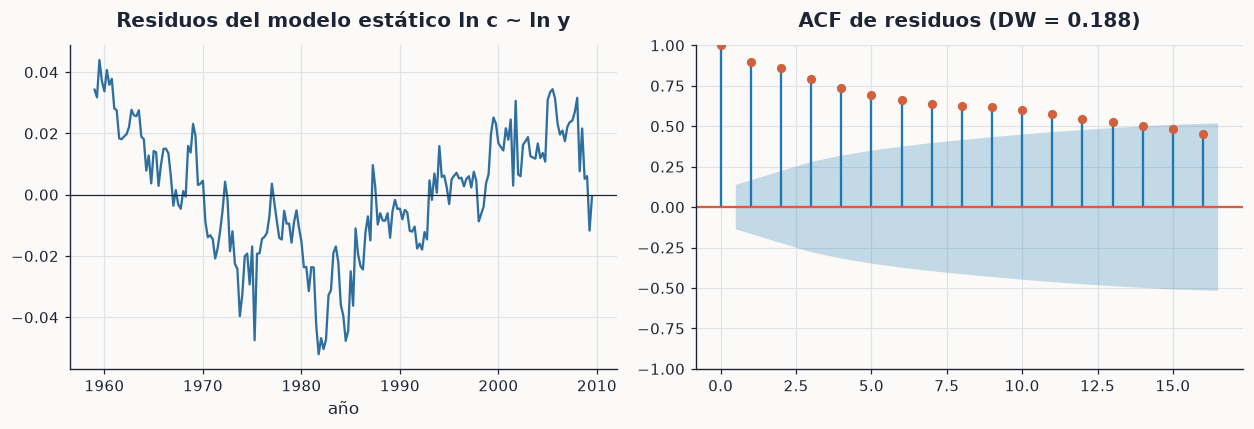

In [30]:
dw_orig = durbin_watson(m_red.resid)
dw_perm = durbin_watson(m_red.resid.sample(frac=1, random_state=0).values)
print(f"wage2: DW (orden original) = {dw_orig:.3f};  DW (filas reordenadas) = {dw_perm:.3f}")
R["dw_wage2"] = [dw_orig, dw_perm]

mac = sm.datasets.macrodata.load_pandas().data
mac["fecha"] = pd.PeriodIndex.from_fields(year=mac.year.astype(int), quarter=mac.quarter.astype(int), freq="Q").to_timestamp()
mac["lc"], mac["ly"] = np.log(mac.realcons), np.log(mac.realdpi)
m_est = smf.ols("lc ~ ly", mac).fit()
bg_e = acorr_breusch_godfrey(m_est, nlags=4)
m_hac = smf.ols("lc ~ ly", mac).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
rho = np.corrcoef(m_est.resid[1:], m_est.resid[:-1])[0, 1]
R["autocorr"] = dict(n=int(m_est.nobs), b=m_est.params["ly"], se=m_est.bse["ly"], se_hac=m_hac.bse["ly"], R2=m_est.rsquared,
                     dw=durbin_watson(m_est.resid), rho=rho, dw_aprox=2 * (1 - rho), bg_LM=bg_e[0], bg_p=bg_e[1])
print(R["autocorr"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4))
a1.plot(mac.fecha, m_est.resid, color=AZUL)
a1.axhline(0, color=TINTA, lw=.8)
a1.set(title="Residuos del modelo estático ln c ~ ln y", xlabel="año")
sm.graphics.tsa.plot_acf(m_est.resid, lags=16, ax=a2, color=NARANJA)
a2.set_title(f"ACF de residuos (DW = {R['autocorr']['dw']:.3f})")
guardar("autocorrelacion")

## 16. (5.11–5.12) Modelos dinámicos y rezagos — consumo de EE. UU.
ARDL(1,1): $\ln c_t=\alpha+\phi\ln c_{t-1}+\beta_0\ln y_t+\beta_1\ln y_{t-1}+u_t$.
Multiplicador de largo plazo: $(\beta_0+\beta_1)/(1-\phi)$. Los rezagos de una serie con tendencia son casi
idénticos entre sí: **multicolinealidad entre rezagos** (las notas lo advierten en 15.2).

In [31]:
mac["lc_1"], mac["ly_1"] = mac.lc.shift(1), mac.ly.shift(1)
md = mac.dropna(subset=["lc_1", "ly_1"])
m_ardl = smf.ols("lc ~ lc_1 + ly + ly_1", md).fit()
phi, b0_, b1_ = m_ardl.params["lc_1"], m_ardl.params["ly"], m_ardl.params["ly_1"]
bg_a = acorr_breusch_godfrey(m_ardl, nlags=4)
vif_ardl = vif_tabla(md[["lc_1", "ly", "ly_1"]])
R["ardl"] = dict(params=m_ardl.params.to_dict(), p=m_ardl.pvalues.to_dict(), R2=m_ardl.rsquared, phi=phi,
                 lr=(b0_ + b1_) / (1 - phi), bg_LM=bg_a[0], bg_p=bg_a[1], vif=vif_ardl.VIF.to_dict(),
                 corr_y_y1=md[["ly", "ly_1"]].corr().iloc[0, 1])
print(m_ardl.summary().tables[1])
print(f"φ = {phi:.4f} (|φ|<1 → estable);  multiplicador LP = {(b0_+b1_)/(1-phi):.4f}")
print(vif_ardl)

# Rezagos distribuidos en tasas de crecimiento (estacionarias): Δln c_t sobre Δln y_{t-j}
mac["dc"], mac["dy"] = mac.lc.diff() * 100, mac.ly.diff() * 100
for j in range(1, 5):
    mac[f"dy_{j}"] = mac.dy.shift(j)
dl_rows = []
base_dl = mac.dropna(subset=["dc", "dy", "dy_4"])
for p in range(0, 5):
    f = "dc ~ dy" + "".join(f" + dy_{j}" for j in range(1, p + 1))
    m = smf.ols(f, base_dl).fit()
    dl_rows.append({"rezagos": p, "AIC": m.aic, "BIC": m.bic, "suma_betas": sum(m.params[c] for c in m.params.index if c != "Intercept"),
                    "R2_aj": m.rsquared_adj})
p_bic = min(dl_rows, key=lambda r_: r_["BIC"])["rezagos"]
p_aic = min(dl_rows, key=lambda r_: r_["AIC"])["rezagos"]
lags = ["dy"] + [f"dy_{j}" for j in range(1, p_bic + 1)]
m_dl = smf.ols("dc ~ " + " + ".join(lags), base_dl).fit()
R["rezagos"] = dict(tabla=dl_rows, p_bic=p_bic, p_aic=p_aic, params=m_dl.params.to_dict(), p=m_dl.pvalues.to_dict(),
                    acumulado=m_dl.params[lags].sum())
print(f"BIC elige {p_bic} rezago(s); AIC elige {p_aic}. Efecto acumulado (BIC) = {m_dl.params[lags].sum():.3f}")
pd.DataFrame(dl_rows)

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0010      0.012      0.087      0.931      -0.022       0.024
lc_1           0.9539      0.022     43.693      0.000       0.911       0.997
ly             0.3450      0.050      6.860      0.000       0.246       0.444
ly_1          -0.2989      0.051     -5.856      0.000      -0.400      -0.198
φ = 0.9539 (|φ|<1 → estable);  multiplicador LP = 0.9992
           VIF  Tolerancia
ly_1 3208.5844      0.0003
ly   3095.1500      0.0003
lc_1  626.3246      0.0016
BIC elige 1 rezago(s); AIC elige 3. Efecto acumulado (BIC) = 0.602


,rezagos,AIC,BIC,suma_betas,R2_aj
0,0,379.5857,386.1622,0.3418,0.1897
1,1,355.7872,365.6520,0.6019,0.2850
2,2,356.0085,369.1616,0.6601,0.2878
3,3,353.5927,370.0340,0.7457,0.2999
4,4,355.5915,375.3211,0.7443,0.2962


**Lectura:** en el ARDL, $|\hat\phi|<1$ (estable) y el multiplicador de largo plazo ≈ 1: en el largo plazo el
consumo crece en la misma proporción que el ingreso. Los VIF de $\ln y_t$, $\ln y_{t-1}$ y $\ln c_{t-1}$ son
enormes porque las series casi no cambian de un trimestre a otro. BG todavía rechaza en el ARDL, así que la
dinámica no está completa: conviene más rezagos o inferencia HAC. Como DW no es válido con la dependiente
rezagada, usamos BG. En niveles con tendencia hay riesgo de regresión espuria; por eso el modelo de rezagos
distribuidos se estima en tasas de crecimiento. Ahí BIC elige el modelo más parsimonioso (lo esperado según
las notas: BIC penaliza más que AIC).

## 17. (5.13) Prueba de Jarque–Bera: $JB=\frac n6\left(S^2+\frac{(K-3)^2}{4}\right)\sim\chi^2_2$

In [32]:
res = m_red.resid
S = stats.skew(res)
K = stats.kurtosis(res, fisher=False)
JB_manual = n / 6 * (S ** 2 + (K - 3) ** 2 / 4)
jb = jarque_bera(res)
R["jb"] = dict(S=S, K=K, JB=JB_manual, p=jb[1], crit=stats.chi2.ppf(.95, 2), jb_capm=R["finanzas"]["jb"])
print(f"S = {S:.4f}, K = {K:.4f}, JB = {JB_manual:.2f} (statsmodels {jb[0]:.2f}), p = {jb[1]:.2e}, crítico χ²(2) = 5.991")
reset = linear_reset(m_red, power=3, use_f=True)
R["reset"] = dict(F=float(reset.fvalue), p=float(reset.pvalue))
print(f"RESET: F = {reset.fvalue:.3f}, p = {reset.pvalue:.3f}")

S = -0.3034, K = 4.8489, JB = 113.91 (statsmodels 113.91), p = 1.84e-25, crítico χ²(2) = 5.991
RESET: F = 0.846, p = 0.430


**Lectura:** JB ≈ 114 ≫ 5.99 → se rechaza normalidad (colas pesadas: K ≈ 4.8, y asimetría negativa).
Con n = 722 la inferencia es válida asintóticamente; rechazar JB **no** implica sesgo de MCO.
RESET (p ≈ 0.43) no detecta problemas de forma funcional.

## 18. Inferencia vs predicción (scikit-learn)

In [33]:
Xtr, Xte, ytr, yte = train_test_split(df, df.lwage, test_size=0.2, random_state=42)
pred_rows = []
for nom, f in [("Base", f_base), ("Completo", f_full), ("Reducido", f_red)]:
    m = smf.ols(f, Xtr).fit()
    yp = m.predict(Xte)
    pred_rows.append({"modelo": nom, "R2_test": r2_score(yte, yp), "RMSE_test": mean_squared_error(yte, yp) ** .5})
sc2 = StandardScaler().fit(Xr.loc[Xtr.index])
rg = RidgeCV(alphas=np.logspace(-3, 4, 200)).fit(sc2.transform(Xr.loc[Xtr.index]), ytr)
yp = rg.predict(sc2.transform(Xr.loc[Xte.index]))
pred_rows.append({"modelo": "Ridge", "R2_test": r2_score(yte, yp), "RMSE_test": mean_squared_error(yte, yp) ** .5})
R["prediccion"] = pred_rows
pd.DataFrame(pred_rows)

,modelo,R2_test,RMSE_test
0,Base,0.0405,0.3705
1,Completo,0.2239,0.3332
2,Reducido,0.2215,0.3338
3,Ridge,0.2504,0.3275


**Lectura:** fuera de muestra, el modelo completo (con multicolinealidad) y el reducido predicen casi igual:
la multicolinealidad daña la **interpretación** de coeficientes individuales, no la **predicción**. Ridge
mejora un poco el RMSE a cambio de coeficientes sesgados (no se reportan p-values de Ridge).

## 19. Conclusiones

1. **Simple:** un año más de educación se asocia con ≈ 6% más salario, pero esa cifra mezcla educación y
   habilidad (sesgo por variable omitida): baja a ≈ 4–5% al controlar IQ y entorno familiar.
2. **Multicolinealidad perfecta** (age, educ y age − educ − 6): rango deficiente, no hay MCO único.
3. **Imperfecta:** VIF > 20 en exper y exper², número de condición alto, Farrar–Glauber rechaza ortogonalidad;
   exper, exper² y age no son significativas una por una pero sí conjuntamente (prueba F).
4. **No sesga, imprecisa:** MCO sigue siendo MELI; la multicolinealidad infla las varianzas. Centrar, combinar,
   PCA y Ridge la reducen; el retorno a la educación se mantiene robusto.
5. **Diagnóstico:** BP sugiere heteroscedasticidad → errores HC; JB rechaza normalidad pero n es grande;
   RESET no detecta mala especificación; la autocorrelación sólo tiene sentido en series de tiempo, donde
   el modelo estático de consumo la presenta severa (DW ≈ 0.19); el ARDL estable la reduce, pero BG
   sigue rechazando, de modo que la inferencia debe ser HAC o la dinámica debe ampliarse.
6. La misma lección aparece en hedónicos (avalúo vs superficie), finanzas (acciones correlacionadas) y
   rezagos (ln y_t vs ln y_{t-1}).

In [34]:
def a_json(o):
    if isinstance(o, dict):
        return {str(k_): a_json(v) for k_, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [a_json(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, np.bool_):
        return bool(o)
    return o


(FIG.parent / "resultados.json").write_text(json.dumps(a_json(R), ensure_ascii=False, indent=1))
print("Resultados guardados en resultados.json")

Resultados guardados en resultados.json
